In [3]:
import os
import pickle as pkl
import pandas as pd

from pydeseq2.dds import DeseqDataSet
from pydeseq2.default_inference import DefaultInference
from pydeseq2.ds import DeseqStats
from pydeseq2.utils import load_example_data

In [4]:
def check_id_duplicate(df, column_name):
    if df[column_name].duplicated().any():
        raise ValueError(f"dataframe: '{df}' , its' column: '{column_name}' has duplicate values")

In [5]:
base_path = "../../../../2nd_6samples_output"
# total_df_original = pd.read_csv(os.path.join(base_path, "total_meet_at_least_one_condition.csv"), sep=",")
df = pd.read_csv(os.path.join(base_path, "dataset2_DSS_then_control_all_seuquences.csv"), sep=",")
check_id_duplicate(df, "sequence")


target_cols = ['SRR18078869','SRR18078868','SRR18078867','SRR18078872','SRR18078871','SRR18078870']
df[target_cols] = df[target_cols].replace(1, 0)
total_df = df[~(df[target_cols] == 0).all(axis=1)]
# total_df.to_csv(os.path.join(base_path, "dataset2.csv"), sep=",")
# check_id_duplicate(df, "sequence")


# first set the first column as index
total_df.set_index('sequence', inplace=True)
# print(total_df.head())
###add normalization: each value in column/the sum of each column.
columns_normalize = total_df.columns
df_normalized_total = total_df.copy()
df_normalized_total[columns_normalize] = total_df[columns_normalize].div(total_df[columns_normalize].sum())
# print(df_normalized_total[columns_normalize].head())
df_normalized_total[columns_normalize] = df_normalized_total[columns_normalize].mul(10**6).astype(int)

total_df_transposed_normalized = total_df.T
# print(total_df_transposed_normalized.head())

# # print("unnormalized total_df:",total_df)
# total_df_transposed = total_df.T

meta_data = {'condition': ['D', 'D', 'D', 'C', 'C', 'C'], 'group': ['D', 'D', 'D', 'C', 'C', 'C']}
meta_data_total_df = pd.DataFrame(meta_data, index=["SRR18078869", "SRR18078868", "SRR18078867","SRR18078872", "SRR18078871", "SRR18078870"])
print(meta_data_total_df)

            condition group
SRR18078869         D     D
SRR18078868         D     D
SRR18078867         D     D
SRR18078872         C     C
SRR18078871         C     C
SRR18078870         C     C


In [6]:
inference = DefaultInference(n_cpus=1)

dds_total = DeseqDataSet(
    counts=total_df_transposed_normalized,
    metadata=meta_data_total_df,
    design_factors="condition",
    refit_cooks=True,
    inference=inference,
    # n_cpus=8, # n_cpus can be specified here or in the inference object
)
dds_total.deseq2()
stat_res_D_vs_C_total = DeseqStats(dds_total, contrast=["condition", "D", "C"], inference=inference)
stat_res_D_vs_C_total.summary()

/tmp/ipykernel_3379813/67577416.py:3: DeprecationWarning: design_factors is deprecated and will soon be removed.Please consider providing a formulaic formula using the design argumentinstead.
  dds_total = DeseqDataSet(
Fitting size factors...
... done in 0.03 seconds.



Using None as control genes, passed at DeseqDataSet initialization


Fitting dispersions...
... done in 96.76 seconds.

Fitting dispersion trend curve...
/home/yaolab/mzhou10/.conda/envs/pydeseq2_env/lib/python3.10/site-packages/pydeseq2/dds.py:807: UserWarning: The dispersion trend curve fitting did not converge. Switching to a mean-based dispersion trend.
  self._fit_parametric_dispersion_trend(vst)
... done in 2.90 seconds.

Fitting MAP dispersions...
... done in 84.44 seconds.

Fitting LFCs...
... done in 141.05 seconds.

Calculating cook's distance...
... done in 0.10 seconds.

Replacing 0 outlier genes.

Running Wald tests...
... done in 17.69 seconds.



Log2 fold change & Wald test p-value: condition D vs C
                             baseMean  log2FoldChange     lfcSE      stat  \
sequence                                                                    
CCCACCCCCCGTCGCCTCCG        87.586638        9.817574  3.585336  2.738258   
GGAGAAGCCGGCGGGAGCC       7032.869041        8.923558  2.538846  3.514808   
CGGAGAAGCCGGCGGGAGCCCCGG  4490.829281        6.385095  2.506366  2.547551   
TCCCGCCGTCGCCGTCCCCGCT     151.028152        9.089016  3.529654  2.575044   
GCACCCGTAGCTCAGCTGG         40.459486        8.703639  4.207660  2.068523   
...                               ...             ...       ...       ...   
AGGCTAAATACCGGCACGAGAC       0.238915       -1.720373  4.348962 -0.395583   
CCCTTTCACGGCGGTAACACG        0.238915       -1.720373  4.348962 -0.395583   
GGGAGTGAAAGAGAACCTGAACC      0.238915       -1.720373  4.348962 -0.395583   
GGTGAAATTGTAATCCCGGTGA       0.238915       -1.720373  4.348962 -0.395583   
ACGCTGGCGGCAGGCTTA   

In [7]:

df_stat_res_D_vs_C_total = stat_res_D_vs_C_total.results_df 
# print(df_stat_res_E_vs_F_total.head())
# df_stat_res_E_vs_F_ecoli = stat_res_E_vs_F_ecoli.results_df 
df_stat_res_D_vs_C_total_sorted = df_stat_res_D_vs_C_total.sort_values(by='padj', ascending=True)
print(df_stat_res_D_vs_C_total_sorted.head())
# print(df_stat_res_E_vs_F_total_sorted.columns)
# check_id_duplicate(df_stat_res_E_vs_F_total_sorted, "sequence")
# df_stat_res_E_vs_F_ecoli_sorted = df_stat_res_E_vs_F_ecoli.sort_values(by='padj', ascending=True)
#print(df_stat_res_E_vs_F_total_sorted.head())
SAVE = True  # whether to save the outputs of this notebook
if SAVE:
    df_stat_res_D_vs_C_total_sorted.to_csv(os.path.join(base_path, "DESeq2_results_D_vs_C_all_sequence_count_normalize.csv"), index=True)
    # df_stat_res_E_vs_F_total_sorted.to_csv(os.path.join(base_path, "DESeq2_results_E_vs_F_total_sequence_normalize_input_at_least_4_samples.csv"), index=True)
    

                             baseMean  log2FoldChange     lfcSE      stat  \
sequence                                                                    
GTAAAGGGAGCGCAGACGGC         3.920745       -5.548962  4.219266 -1.315149   
GGAGTAACGACTTGGGCGCT         2.817283       -5.073039  4.223764 -1.201071   
GAGAAGCATTGTTAAGGAACTCG      1.126913       -3.749952  4.247669 -0.882826   
GCTAGTAATCGCGGATCAGCATG     18.652278       -7.799488  3.628970 -2.149229   
CGTGATGGGGATCGGGGATTGCAATT   1.092384       -3.724967  3.944594 -0.944322   

                              pvalue      padj  
sequence                                        
GTAAAGGGAGCGCAGACGGC        0.188460  0.716035  
GGAGTAACGACTTGGGCGCT        0.229724  0.716035  
GAGAAGCATTGTTAAGGAACTCG     0.377330  0.716035  
GCTAGTAATCGCGGATCAGCATG     0.031616  0.716035  
CGTGATGGGGATCGGGGATTGCAATT  0.345005  0.716035  


aaa
sequence  CGGAGAAGCCGGCGGGAGCC  TGGTGAACTATGCCTGGGC  CGAAGCGGGGCTGGGCGCGCGC  \
Con                   0.000000             0.000000                0.000000   
DSS                  10.759878            11.035042               10.896141   

sequence  CCGCCGGTGAAATACCACTACT  CGGAGAAGCCGGCGGGAGCCC  TGGACGCGAGCCGGGCCCT  \
Con                     0.000000               0.000000             0.000000   
DSS                   -14.618987              10.003553            12.490642   

sequence  TCTGGACGCGAGCCGGGCCC  ACCCTGTCTGAACATGGGGGGACC  CGGACCACCCCGCCCCGAG  \
Con                   0.000000                  0.000000              0.00000   
DSS                  12.820919                 12.050583             12.22403   

sequence  CTGGAATCGCTAGTAATCGC  ...  TTCCCGTGGATCGCCCCAGC  \
Con                   0.000000  ...              0.000000   
DSS                 -14.035004  ...             14.290067   

sequence  CTCTCCCCCCGGCCTCTCC  TCCTCCGGCCTCGTCCTCCCCC  TCTGGACGCGAGCCGGGCCCT  \
Con      

/tmp/ipykernel_1610705/3404313667.py:75: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.ax.set_yticklabels(cbar.ax.get_yticklabels(), fontproperties=arial_font)


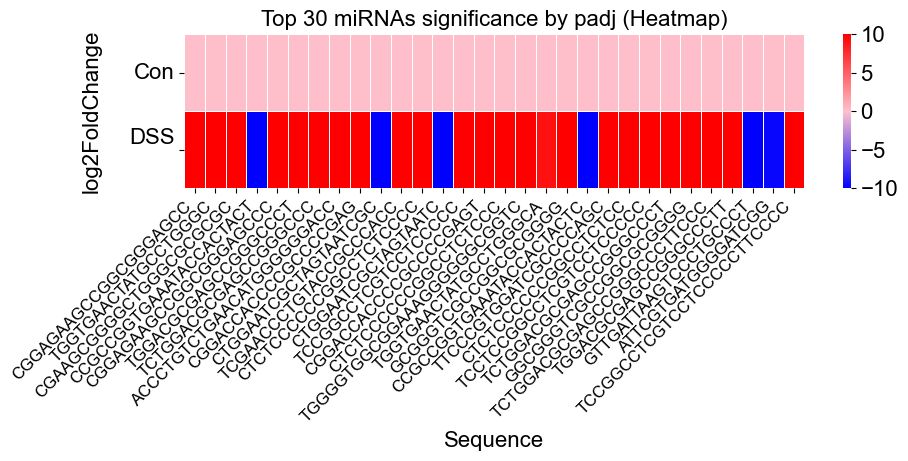

In [1]:

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm


fm.fontManager.addfont(str("arial.ttf"))


arial_font = fm.FontProperties(fname="arial.ttf", size=16)
arial_font_small = fm.FontProperties(fname="arial.ttf", size=12)
print("aaa")

# df = pd.read_csv(...)
base_path = "../../../../2nd_6samples_output"
file_path = os.path.join(base_path, "DESeq2_results_D_vs_C_sequence_count_normalize.csv")
df = pd.read_csv(file_path, sep=",", usecols=["sequence","log2FoldChange","padj"])

df = df.dropna(subset=["padj", "log2FoldChange"])
df = df.replace({'padj': 0}, 1e-300)  


top_df = df.nsmallest(30, 'padj')


custom_cmap = LinearSegmentedColormap.from_list(
    "custom_diverging",
    ["blue", "pink", "red"]  
)
heatmap_data = pd.DataFrame({
    'Con': np.zeros(len(top_df)),
    'DSS': top_df['log2FoldChange'].values
}, index=top_df['sequence']).T  
print(heatmap_data)

significant = top_df['padj'] < 0.05


plt.figure(figsize=(10, 2))
# ax = sns.heatmap(
#     heatmap_data,
#     cmap="RdBu_r",
#     vmin=-3, vmax=1,
#     cbar_kws={'label': ''},
#     linewidths=0.5,
#     linecolor='white'
# )
ax = sns.heatmap(
    heatmap_data,
    cmap=custom_cmap,
    vmin=-10, vmax=10,
    cbar_kws={'label': ''},
    linewidths=0.5,
    linecolor='white'
)

# for col_idx, (gene, sig) in enumerate(zip(top_df['sequence'], significant)):
#     if sig:
#         ax.add_patch(plt.Circle((col_idx + 0.5, 0.5), 0.08, color='black', zorder=10))
# cbar = ax.collections[0].colorbar
# cbar.set_label("log2FoldChange", fontproperties=arial_font, labelpad=20)  # bigger & move outward


ax.set_xlabel("Sequence", fontproperties=arial_font)
ax.set_xticklabels(top_df['sequence'], rotation=45, ha='right',fontproperties=arial_font_small)
ax.set_yticklabels(['Con', 'DSS\n'], rotation=0,fontproperties=arial_font)
ax.set_ylabel("log2FoldChange", fontproperties=arial_font, labelpad=20)
plt.title('Top 30 miRNAs significance by padj (Heatmap)',fontproperties=arial_font)
cbar = ax.collections[0].colorbar
# cbar.set_label("Expression", fontproperties=arial_font, size=12)
cbar.ax.set_yticklabels(cbar.ax.get_yticklabels(), fontproperties=arial_font)
# plt.legend()
# plt.grid(True)
# plt.show()
plt.savefig("figure2_F.pdf", format="pdf", bbox_inches="tight")


In [2]:
filtered_red = top_df[top_df["log2FoldChange"] > 0]
print(filtered_red['sequence'])
filtered_blue = top_df[top_df["log2FoldChange"] < 0]
print(filtered_blue['sequence'])
    # if temp['log2FoldChange'].values < 0:
    #     print(temp['sequence'])

# CCGCCGGTGAAATACCACTACT
# CTGGAATCGCTAGTAATCGC
# GTTGATTAAGTCCCTGCCCT
# ATTCGTGATGGGGATCGG

0          CGGAGAAGCCGGCGGGAGCC
1           TGGTGAACTATGCCTGGGC
2        CGAAGCGGGGCTGGGCGCGCGC
4         CGGAGAAGCCGGCGGGAGCCC
5           TGGACGCGAGCCGGGCCCT
6          TCTGGACGCGAGCCGGGCCC
7      ACCCTGTCTGAACATGGGGGGACC
8           CGGACCACCCCGCCCCGAG
10        TCGAACCCTGTACCGCCCACC
11        CTCTCCCCCCGGCCTCTCCCC
13          TCCGGCCTCGTCCTCCCCC
14         CGGACCACCCCGCCCCGAGT
15         CTCTCCCCCCGGCCTCTCCC
16    TGGGGTGGCGGAAAGGGGGGCGGTC
17         TGGTGAACTATGCCTGGGCA
18          GCGGGTCGCCGGCGCGGGG
20         TTCCCGTGGATCGCCCCAGC
21          CTCTCCCCCCGGCCTCTCC
22       TCCTCCGGCCTCGTCCTCCCCC
23        TCTGGACGCGAGCCGGGCCCT
24         GGCGGGTCGCCGGCGCGGGG
25    TCTGGACGCGAGCCGGGCCCTTCCC
26         TGGACGCGAGCCGGGCCCTT
29    TCCGGCCTCGTCCTCCCCCTTCCCC
Name: sequence, dtype: object
3      CCGCCGGTGAAATACCACTACT
9        CTGGAATCGCTAGTAATCGC
12         CTGGAATCGCTAGTAATC
19    CCGCCGGTGAAATACCACTACTC
27       GTTGATTAAGTCCCTGCCCT
28         ATTCGTGATGGGGATCGG
Name: sequence, dtype:

In [5]:
df = pd.read_csv(os.path.join(base_path, "dataset2_DSS_then_control_meet_at_least_one_condition_common_sequences.csv"), sep=",")
merged = pd.merge(filtered_red['sequence'], df, on='sequence', how='left')
# print(merged)
cols_to_sum = ['SRR18078869','SRR18078868','SRR18078867','SRR18078872','SRR18078871','SRR18078870']
filtered = merged[(merged[cols_to_sum] != 0).all(axis=1)]
# print(filtered)
filtered["total"] = filtered[cols_to_sum].sum(axis=1)
# print(merged)
df_sorted = filtered.sort_values(by="total")
print(df_sorted)

                 sequence  SRR18078869  SRR18078868  SRR18078867  SRR18078872  \
14   TGGTGAACTATGCCTGGGCA      12362.0        330.0       4485.0          8.0   
1     TGGTGAACTATGCCTGGGC      24251.0        266.0       8627.0          4.0   
3   CGGAGAAGCCGGCGGGAGCCC     196401.0       3137.0      13691.0         43.0   
0    CGGAGAAGCCGGCGGGAGCC     266578.0       8777.0      38328.0         34.0   

    SRR18078871  SRR18078870     total  
14          3.0         15.0   17203.0  
1           1.0         10.0   33159.0  
3          15.0        109.0  213396.0  
0          28.0         77.0  313822.0  


/tmp/ipykernel_1610705/2306834595.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered["total"] = filtered[cols_to_sum].sum(axis=1)


In [7]:
df = pd.read_csv(os.path.join(base_path, "dataset2_DSS_then_control_meet_at_least_one_condition_common_sequences.csv"), sep=",")
merged = pd.merge(filtered_blue['sequence'], df, on='sequence', how='left')
# print(merged)
cols_to_sum = ['SRR18078869','SRR18078868','SRR18078867','SRR18078872','SRR18078871','SRR18078870']
merged["total"] = merged[cols_to_sum].sum(axis=1)
# print(merged)
df_sorted = merged.sort_values(by="total")
print(df_sorted)


                  sequence  SRR18078869  SRR18078868  SRR18078867  \
5       ATTCGTGATGGGGATCGG          2.0          2.0          0.0   
4     GTTGATTAAGTCCCTGCCCT          0.0          0.0          0.0   
1     CTGGAATCGCTAGTAATCGC          0.0          0.0          0.0   
2       CTGGAATCGCTAGTAATC          0.0          0.0          0.0   
3  CCGCCGGTGAAATACCACTACTC          0.0          0.0          0.0   
0   CCGCCGGTGAAATACCACTACT          0.0          0.0          0.0   

   SRR18078872  SRR18078871  SRR18078870    total  
5        874.0        705.0       2092.0   3675.0  
4       1230.0       1360.0       2204.0   4794.0  
1       3547.0       3368.0        433.0   7348.0  
2       3445.0       4338.0        258.0   8041.0  
3        779.0       1445.0       6497.0   8721.0  
0       1829.0       3338.0       9698.0  14865.0  


In [ ]:
red:  CGGAGAAGCCGGCGGGAGCC
blue:  ATTCGTGATGGGGATCGG

In [ ]:
20       TTCCCGTGGATCGCCCCAGC  except  72,71, 70.sample   573/
6        TCTGGACGCGAGCCGGGCCC   except    72,71. sample   573|1447|1384
17       TGGTGAACTATGCCTGGGCA     1447|1382
1         TGGTGAACTATGCCTGGGC     1447|1382
4       CGGAGAAGCCGGCGGGAGCCC    1447|1382
0        CGGAGAAGCCGGCGGGAGCC     1382|1447

In [ ]:
red_sequence = pd.DataFrame({
    "sequence": ["CGGAGAAGCCGGCGGGAGCC"]
})

{'Lachnoclostridium edouardi': 'black', 'Blautia liquoris': 'firebrick', 'Stomatobaculum longum': 'orange', 'Pseudomonas avellanae': 'green', 'Acholeplasma granularum': 'limegreen', 'Roseovarius nitratireducens': 'gray', 'Undibacterium baiyunense': 'hotpink', 'Borrelia hispanica CRI': 'lightgray', 'Nocardioides oceani': 'purple', 'Sulfitobacter noctilucae': 'rosybrown', 'Borrelia persica No12': 'purple', 'Paenibacillus aceti': 'darkorange', 'Ectobacillus ponti': 'red', 'Paraclostridium dentum': 'chocolate', 'Xanthomonas sontii': 'deepskyblue', 'Deinococcus aestuarii': 'yellowgreen', 'Alsobacter ponti': 'navy', 'Microbacterium karelineae': 'blue', 'Hyphomonas sediminis': 'yellow', 'Undibacterium luofuense': 'plum', 'Pantoea endophytica': 'tomato', 'Vibrio marinisediminis': 'salmon', 'Pseudomonas fulva': 'tan', 'Xanthomonas albilineans': 'thistle', 'Yersinia thracica': 'mistyrose', 'Klebsiella michiganensis': 'black', 'Yersinia pekkanenii': 'firebrick', 'Yersinia bercovieri': 'orange'}
{'Lachnoclostridium edouardi': 'black', 'Blautia liquoris': 'firebrick', 'Stomatobaculum longum': 'orange', 'Pseudomonas avellanae': 'green', 'Acholeplasma granularum': 'limegreen', 'Roseovarius nitratireducens': 'gray', 'Undibacterium baiyunense': 'hotpink', 'Borrelia hispanica CRI': 'lightgray', 'Sulfitobacter noctilucae': 'rosybrown', 'Nocardioides oceani': 'darkorange', 'Paenibacillus aceti': 'red', 'Ectobacillus ponti': 'chocolate', 'Paraclostridium dentum': 'deepskyblue', 'Xanthomonas sontii': 'yellowgreen', 'Deinococcus aestuarii': 'navy', 'Alsobacter ponti': 'blue', 'Hyphomonas sediminis': 'yellow', 'Undibacterium luofuense': 'plum', 'Microbacterium karelineae': 'tomato', 'Yersinia thracica': 'salmon', 'Klebsiella michiganensis': 'tan', 'Pseudomonas fulva': 'thistle', 'Yersinia pekkanenii': 'mistyrose', 'Xanthomonas albilineans': 'cyan', 'Yersinia bercovieri': 'pink'}

In [17]:
df_1 = pd.read_csv(os.path.join(base_path, "SRR18078867/produce_final_form/summary_statistics_table.csv"), sep=",")
# print(df_1)
merged = pd.merge(red_sequence['sequence'], df_1, on='sequence', how='left')
# print(merged_1)
df_2 = pd.read_csv(os.path.join(base_path, "SRR18078867/produce_final_form/ID_mapping_species_table.csv"), sep=",")
merged_expanded = (
    merged.assign(seperate_id=merged['internal_ID'].str.split('|'))
    .explode('seperate_id')
    .drop(columns='internal_ID'))

merged_expanded['seperate_id'] = merged_expanded['seperate_id'].astype(str)
# print(merged_expanded)
merged_final = merged_expanded[[ "sequence", "seperate_id"]]
df_2['internal_ID'] = df_2['internal_ID'].astype(str)

final = pd.merge(merged_final, df_2, left_on="seperate_id", right_on="internal_ID", how='left')
print(final)

'Paenibacillus aceti': 'red'
'Deinococcus aestuarii': 'navy'



               sequence seperate_id         SACC_refseqID  \
0  CGGAGAAGCCGGCGGGAGCC        1382         NZ_KZ987726.1   
1  CGGAGAAGCCGGCGGGAGCC        1447  NZ_JAHKSN010000042.1   

                                                name internal_ID  
0           Paenibacillus aceti strain L14 Scaffold6        1382  
1  Deinococcus aestuarii strain SYSU M49105 NODE_...        1447  


In [18]:
df_1 = pd.read_csv(os.path.join(base_path, "SRR18078868/produce_final_form/summary_statistics_table.csv"), sep=",")
# print(df_1)
merged = pd.merge(red_sequence['sequence'], df_1, on='sequence', how='left')
# print(merged)
df_2 = pd.read_csv(os.path.join(base_path, "SRR18078868/produce_final_form/ID_mapping_species_table.csv"), sep=",")
merged_expanded = (
    merged.assign(seperate_id=merged['internal_ID'].str.split('|'))
    .explode('seperate_id')
    .drop(columns='internal_ID'))

merged_expanded['seperate_id'] = merged_expanded['seperate_id'].astype(str)
# print(merged_expanded)
merged_final = merged_expanded[[ "sequence", "seperate_id"]]
df_2['internal_ID'] = df_2['internal_ID'].astype(str)

final = pd.merge(merged_final, df_2, left_on="seperate_id", right_on="internal_ID", how='left')
print(final)
# merged.to_csv(os.path.join(base_path, "sacc_name.csv"), index=True)

'Deinococcus aestuarii': 'navy'
'Paenibacillus aceti': 'red'
'Microbacterium karelineae': 'tomato'
'Xanthomonas sontii': 'yellowgreen'
'Paraclostridium dentum': 'deepskyblue'

               sequence seperate_id         SACC_refseqID  \
0  CGGAGAAGCCGGCGGGAGCC        1149  NZ_JAHKSN010000042.1   
1  CGGAGAAGCCGGCGGGAGCC        1593     NZ_WFIX01000174.1   
2  CGGAGAAGCCGGCGGGAGCC        1186         NZ_KZ987726.1   
3  CGGAGAAGCCGGCGGGAGCC        1439     NZ_WJPN01000037.1   
4  CGGAGAAGCCGGCGGGAGCC        1317     NZ_WIPK01000182.1   

                                                name internal_ID  
0  Deinococcus aestuarii strain SYSU M49105 NODE_...        1149  
1     Microbacterium karelineae strain TRM 80801 394        1593  
2           Paenibacillus aceti strain L14 Scaffold6        1186  
3      Xanthomonas sontii strain ASD011 scf_13134_37        1439  
4  Paraclostridium dentum strain SKVG24 NODE_276_...        1317  


In [19]:
df_1 = pd.read_csv(os.path.join(base_path, "SRR18078869/produce_final_form/summary_statistics_table.csv"), sep=",")
# print(df_1)
merged = pd.merge(red_sequence['sequence'], df_1, on='sequence', how='left')
# print(merged_3)
df_2 = pd.read_csv(os.path.join(base_path, "SRR18078869/produce_final_form/ID_mapping_species_table.csv"), sep=",")
merged_expanded = (
    merged.assign(seperate_id=merged['internal_ID'].str.split('|'))
    .explode('seperate_id')
    .drop(columns='internal_ID'))

merged_expanded['seperate_id'] = merged_expanded['seperate_id'].astype(str)
print(merged_expanded)
merged_final = merged_expanded[[ "sequence", "seperate_id"]]
df_2['internal_ID'] = df_2['internal_ID'].astype(str)

final = pd.merge(merged_final, df_2, left_on="seperate_id", right_on="internal_ID", how='left')
print(final)

'Deinococcus aestuarii': 'navy'
'Paenibacillus aceti': 'red'
'Alsobacter ponti': 'blue'
'Pantoea endophytica' : "not include"
'Hyphomonas sediminis': 'yellow'


               sequence                  percentage(%)  species_count  \
0  CGGAGAAGCCGGCGGGAGCC  20.08|20.02|20.00|19.97|19.92              5   
0  CGGAGAAGCCGGCGGGAGCC  20.08|20.02|20.00|19.97|19.92              5   
0  CGGAGAAGCCGGCGGGAGCC  20.08|20.02|20.00|19.97|19.92              5   
0  CGGAGAAGCCGGCGGGAGCC  20.08|20.02|20.00|19.97|19.92              5   
0  CGGAGAAGCCGGCGGGAGCC  20.08|20.02|20.00|19.97|19.92              5   

  seperate_id  
0        1750  
0        1801  
0        1708  
0         952  
0        1700  
               sequence seperate_id         SACC_refseqID  \
0  CGGAGAAGCCGGCGGGAGCC        1750  NZ_JAHKSN010000042.1   
1  CGGAGAAGCCGGCGGGAGCC        1801  NZ_JANCLU010000048.1   
2  CGGAGAAGCCGGCGGGAGCC        1708         NZ_KZ987726.1   
3  CGGAGAAGCCGGCGGGAGCC         952     NZ_PJRT01000013.1   
4  CGGAGAAGCCGGCGGGAGCC        1700  NZ_JAIEZP010000004.1   

                                                name internal_ID  
0  Deinococcus aestuarii strain

In [20]:
df_1 = pd.read_csv(os.path.join(base_path, "SRR18078870/produce_final_form/summary_statistics_table.csv"), sep=",")
# print(df_1)
merged = pd.merge(red_sequence['sequence'], df_1, on='sequence', how='left')
df_2 = pd.read_csv(os.path.join(base_path, "SRR18078870/produce_final_form/ID_mapping_species_table.csv"), sep=",")
merged_expanded = (
    merged.assign(seperate_id=merged['internal_ID'].str.split('|'))
    .explode('seperate_id')
    .drop(columns='internal_ID'))

merged_expanded['seperate_id'] = merged_expanded['seperate_id'].astype(str)
print(merged_expanded)
merged_final = merged_expanded[[ "sequence", "seperate_id"]]
df_2['internal_ID'] = df_2['internal_ID'].astype(str)

final = pd.merge(merged_final, df_2, left_on="seperate_id", right_on="internal_ID", how='left')
print(final)

'Microbacterium karelineae': 'tomato'
'Xanthomonas sontii': 'yellowgreen'
'Paraclostridium dentum': 'deepskyblue'
'Alsobacter ponti': 'blue'
'Roseovarius nitratireducens': 'gray'


               sequence                  percentage(%)  species_count  \
0  CGGAGAAGCCGGCGGGAGCC  24.68|23.38|19.48|19.48|12.99              5   
0  CGGAGAAGCCGGCGGGAGCC  24.68|23.38|19.48|19.48|12.99              5   
0  CGGAGAAGCCGGCGGGAGCC  24.68|23.38|19.48|19.48|12.99              5   
0  CGGAGAAGCCGGCGGGAGCC  24.68|23.38|19.48|19.48|12.99              5   
0  CGGAGAAGCCGGCGGGAGCC  24.68|23.38|19.48|19.48|12.99              5   

  seperate_id  
0         703  
0        1106  
0         835  
0        1028  
0         470  
               sequence seperate_id         SACC_refseqID  \
0  CGGAGAAGCCGGCGGGAGCC         703     NZ_WIPK01000182.1   
1  CGGAGAAGCCGGCGGGAGCC        1106     NZ_WJPN01000037.1   
2  CGGAGAAGCCGGCGGGAGCC         835     NZ_PDNI01000016.1   
3  CGGAGAAGCCGGCGGGAGCC        1028     NZ_WFIX01000174.1   
4  CGGAGAAGCCGGCGGGAGCC         470  NZ_JANCLU010000048.1   

                                                name internal_ID  
0  Paraclostridium dentum strai

In [21]:
df_1 = pd.read_csv(os.path.join(base_path, "SRR18078871/produce_final_form/summary_statistics_table.csv"), sep=",")
# print(df_1)
merged = pd.merge(red_sequence['sequence'], df_1, on='sequence', how='left')
df_2 = pd.read_csv(os.path.join(base_path, "SRR18078871/produce_final_form/ID_mapping_species_table.csv"), sep=",")
merged_expanded = (
    merged.assign(seperate_id=merged['internal_ID'].str.split('|'))
    .explode('seperate_id')
    .drop(columns='internal_ID'))

merged_expanded['seperate_id'] = merged_expanded['seperate_id'].astype(str)
print(merged_expanded)
merged_final = merged_expanded[[ "sequence", "seperate_id"]]
df_2['internal_ID'] = df_2['internal_ID'].astype(str)

final = pd.merge(merged_final, df_2, left_on="seperate_id", right_on="internal_ID", how='left')
print(final)
'Roseovarius nitratireducens': 'gray'

               sequence percentage(%)  species_count seperate_id
0  CGGAGAAGCCGGCGGGAGCC        100.00              1         135
               sequence seperate_id      SACC_refseqID  \
0  CGGAGAAGCCGGCGGGAGCC         135  NZ_PDNI01000016.1   

                                         name internal_ID  
0  Roseovarius nitratireducens strain TFZ 393         135  


In [22]:
df_1 = pd.read_csv(os.path.join(base_path, "SRR18078872/produce_final_form/summary_statistics_table.csv"), sep=",")
# print(df_1)
merged = pd.merge(red_sequence['sequence'], df_1, on='sequence', how='left')
df_2 = pd.read_csv(os.path.join(base_path, "SRR18078872/produce_final_form/ID_mapping_species_table.csv"), sep=",")
merged_expanded = (
    merged.assign(seperate_id=merged['internal_ID'].str.split('|'))
    .explode('seperate_id')
    .drop(columns='internal_ID'))

merged_expanded['seperate_id'] = merged_expanded['seperate_id'].astype(str)
print(merged_expanded)
merged_final = merged_expanded[[ "sequence", "seperate_id"]]
df_2['internal_ID'] = df_2['internal_ID'].astype(str)

final = pd.merge(merged_final, df_2, left_on="seperate_id", right_on="internal_ID", how='left')
print(final)

'Roseovarius nitratireducens': 'gray'

               sequence percentage(%)  species_count seperate_id
0  CGGAGAAGCCGGCGGGAGCC        100.00              1         228
               sequence seperate_id      SACC_refseqID  \
0  CGGAGAAGCCGGCGGGAGCC         228  NZ_PDNI01000016.1   

                                         name internal_ID  
0  Roseovarius nitratireducens strain TFZ 393         228  


blue sequence

In [23]:
blue_sequence = pd.DataFrame({
    "sequence": ["ATTCGTGATGGGGATCGG"]
})

In [24]:
df_1 = pd.read_csv(os.path.join(base_path, "SRR18078872/produce_final_form/summary_statistics_table.csv"), sep=",")
# print(df_1)
merged = pd.merge(blue_sequence['sequence'], df_1, on='sequence', how='left')
df_2 = pd.read_csv(os.path.join(base_path, "SRR18078872/produce_final_form/ID_mapping_species_table.csv"), sep=",")
merged_expanded = (
    merged.assign(seperate_id=merged['internal_ID'].str.split('|'))
    .explode('seperate_id')
    .drop(columns='internal_ID'))

merged_expanded['seperate_id'] = merged_expanded['seperate_id'].astype(str)
print(merged_expanded)
merged_final = merged_expanded[[ "sequence", "seperate_id"]]
df_2['internal_ID'] = df_2['internal_ID'].astype(str)

final = pd.merge(merged_final, df_2, left_on="seperate_id", right_on="internal_ID", how='left')
print(final)

'Roseovarius nitratireducens': 'gray'

             sequence percentage(%)  species_count seperate_id
0  ATTCGTGATGGGGATCGG        100.00              1         231
             sequence seperate_id      SACC_refseqID  \
0  ATTCGTGATGGGGATCGG         231  NZ_PDNI01000038.1   

                                         name internal_ID  
0  Roseovarius nitratireducens strain TFZ 399         231  


In [25]:
df_1 = pd.read_csv(os.path.join(base_path, "SRR18078871/produce_final_form/summary_statistics_table.csv"), sep=",")
# print(df_1)
merged = pd.merge(blue_sequence['sequence'], df_1, on='sequence', how='left')
df_2 = pd.read_csv(os.path.join(base_path, "SRR18078871/produce_final_form/ID_mapping_species_table.csv"), sep=",")
merged_expanded = (
    merged.assign(seperate_id=merged['internal_ID'].str.split('|'))
    .explode('seperate_id')
    .drop(columns='internal_ID'))

merged_expanded['seperate_id'] = merged_expanded['seperate_id'].astype(str)
print(merged_expanded)
merged_final = merged_expanded[[ "sequence", "seperate_id"]]
df_2['internal_ID'] = df_2['internal_ID'].astype(str)

final = pd.merge(merged_final, df_2, left_on="seperate_id", right_on="internal_ID", how='left')
print(final)

'Roseovarius nitratireducens': 'gray'

             sequence percentage(%)  species_count seperate_id
0  ATTCGTGATGGGGATCGG        100.00              1         138
             sequence seperate_id      SACC_refseqID  \
0  ATTCGTGATGGGGATCGG         138  NZ_PDNI01000038.1   

                                         name internal_ID  
0  Roseovarius nitratireducens strain TFZ 399         138  


In [26]:
df_1 = pd.read_csv(os.path.join(base_path, "SRR18078870/produce_final_form/summary_statistics_table.csv"), sep=",")
# print(df_1)
merged = pd.merge(blue_sequence['sequence'], df_1, on='sequence', how='left')
df_2 = pd.read_csv(os.path.join(base_path, "SRR18078870/produce_final_form/ID_mapping_species_table.csv"), sep=",")
merged_expanded = (
    merged.assign(seperate_id=merged['internal_ID'].str.split('|'))
    .explode('seperate_id')
    .drop(columns='internal_ID'))

merged_expanded['seperate_id'] = merged_expanded['seperate_id'].astype(str)
print(merged_expanded)
merged_final = merged_expanded[[ "sequence", "seperate_id"]]
df_2['internal_ID'] = df_2['internal_ID'].astype(str)

final = pd.merge(merged_final, df_2, left_on="seperate_id", right_on="internal_ID", how='left')
print(final)

'Roseovarius nitratireducens': 'gray'
'Ectobacillus ponti': 'chocolate'
'Microbacterium karelineae': 'tomato'
'Xanthomonas sontii': 'yellowgreen'

             sequence            percentage(%)  species_count seperate_id
0  ATTCGTGATGGGGATCGG  26.24|25.96|24.28|23.52              4        1215
0  ATTCGTGATGGGGATCGG  26.24|25.96|24.28|23.52              4         838
0  ATTCGTGATGGGGATCGG  26.24|25.96|24.28|23.52              4         932
0  ATTCGTGATGGGGATCGG  26.24|25.96|24.28|23.52              4        1111
             sequence seperate_id         SACC_refseqID  \
0  ATTCGTGATGGGGATCGG        1215  NZ_JANCLT010000047.1   
1  ATTCGTGATGGGGATCGG         838     NZ_PDNI01000038.1   
2  ATTCGTGATGGGGATCGG         932     NZ_WFIX01000084.1   
3  ATTCGTGATGGGGATCGG        1111     NZ_WJPN01000041.1   

                                                name internal_ID  
0  Ectobacillus ponti strain SYSU M60031 NODE_52_...        1215  
1         Roseovarius nitratireducens strain TFZ 399         838  
2     Microbacterium karelineae strain TRM 80801 184         932  
3      Xanthomonas sontii strain ASD011 scf_13134_41        1111  

In [27]:
df_1 = pd.read_csv(os.path.join(base_path, "SRR18078869/produce_final_form/summary_statistics_table.csv"), sep=",")
# print(df_1)
merged = pd.merge(blue_sequence['sequence'], df_1, on='sequence', how='left')
df_2 = pd.read_csv(os.path.join(base_path, "SRR18078869/produce_final_form/ID_mapping_species_table.csv"), sep=",")
merged_expanded = (
    merged.assign(seperate_id=merged['internal_ID'].str.split('|'))
    .explode('seperate_id')
    .drop(columns='internal_ID'))

merged_expanded['seperate_id'] = merged_expanded['seperate_id'].astype(str)
print(merged_expanded)
merged_final = merged_expanded[[ "sequence", "seperate_id"]]
df_2['internal_ID'] = df_2['internal_ID'].astype(str)

final = pd.merge(merged_final, df_2, left_on="seperate_id", right_on="internal_ID", how='left')
print(final)

'Microbacterium karelineae': 'tomato'

'Xanthomonas sontii': 'yellowgreen'

             sequence percentage(%)  species_count seperate_id
0  ATTCGTGATGGGGATCGG   50.00|50.00              2         252
0  ATTCGTGATGGGGATCGG   50.00|50.00              2         305
             sequence seperate_id      SACC_refseqID  \
0  ATTCGTGATGGGGATCGG         252  NZ_WJPN01000041.1   
1  ATTCGTGATGGGGATCGG         305  NZ_WFIX01000084.1   

                                             name internal_ID  
0   Xanthomonas sontii strain ASD011 scf_13134_41         252  
1  Microbacterium karelineae strain TRM 80801 184         305  


In [28]:
df_1 = pd.read_csv(os.path.join(base_path, "SRR18078868/produce_final_form/summary_statistics_table.csv"), sep=",")
# print(df_1)
merged = pd.merge(blue_sequence['sequence'], df_1, on='sequence', how='left')
df_2 = pd.read_csv(os.path.join(base_path, "SRR18078868/produce_final_form/ID_mapping_species_table.csv"), sep=",")
merged_expanded = (
    merged.assign(seperate_id=merged['internal_ID'].str.split('|'))
    .explode('seperate_id')
    .drop(columns='internal_ID'))

merged_expanded['seperate_id'] = merged_expanded['seperate_id'].astype(str)
print(merged_expanded)
merged_final = merged_expanded[[ "sequence", "seperate_id"]]
df_2['internal_ID'] = df_2['internal_ID'].astype(str)

final = pd.merge(merged_final, df_2, left_on="seperate_id", right_on="internal_ID", how='left')
print(final)

'Microbacterium karelineae': 'tomato'

             sequence percentage(%)  species_count seperate_id
0  ATTCGTGATGGGGATCGG        100.00              1        1497
             sequence seperate_id      SACC_refseqID  \
0  ATTCGTGATGGGGATCGG        1497  NZ_WFIX01000084.1   

                                             name internal_ID  
0  Microbacterium karelineae strain TRM 80801 184        1497  


In [29]:
df_1 = pd.read_csv(os.path.join(base_path, "SRR18078867/produce_final_form/summary_statistics_table.csv"), sep=",")
# print(df_1)
merged = pd.merge(blue_sequence['sequence'], df_1, on='sequence', how='left')
df_2 = pd.read_csv(os.path.join(base_path, "SRR18078867/produce_final_form/ID_mapping_species_table.csv"), sep=",")
merged_expanded = (
    merged.assign(seperate_id=merged['internal_ID'].str.split('|'))
    .explode('seperate_id')
    .drop(columns='internal_ID'))

merged_expanded['seperate_id'] = merged_expanded['seperate_id'].astype(str)
print(merged_expanded)
merged_final = merged_expanded[[ "sequence", "seperate_id"]]
df_2['internal_ID'] = df_2['internal_ID'].astype(str)

final = pd.merge(merged_final, df_2, left_on="seperate_id", right_on="internal_ID", how='left')
print(final)

             sequence percentage(%)  species_count seperate_id
0  ATTCGTGATGGGGATCGG           NaN            NaN         nan
             sequence seperate_id SACC_refseqID name internal_ID
0  ATTCGTGATGGGGATCGG         nan           NaN  NaN         NaN
